In [2]:
import os

zip_path = "/kaggle/working/data/raw/mimii_fan.zip"
extract_dir = "/kaggle/working/data/mimii"

# 1. Create directories
os.makedirs("/kaggle/working/data/raw", exist_ok=True)
os.makedirs(extract_dir, exist_ok=True)

# 2. Check if dataset is already extracted, or if zip is downloaded
if os.path.exists(extract_dir) and len(os.listdir(extract_dir)) > 0:
    print("✅ Dataset already exists and extracted. Skipping download.")
else:
    # Check if complete zip already exists
    download_needed = True
    if os.path.exists(zip_path):
        size_mb = os.path.getsize(zip_path) / (1024 * 1024)
        if size_mb > 500:
            print(f"📦 Existing zip found ({size_mb:.2f} MB). Skipping download.")
            download_needed = False
        else:
            print(f"⚠️ Incomplete zip found ({size_mb:.2f} MB). Removing and redownloading...")
            os.remove(zip_path)

    # Download if needed
    if download_needed:
        print("📥 Downloading MIMII fan dataset from Zenodo (this may take a few minutes)...")
        !curl -L "https://zenodo.org/record/3678171/files/dev_data_fan.zip?download=1" -o {zip_path}

    # Verify and extract
    if os.path.exists(zip_path):
        file_size = os.path.getsize(zip_path) / (1024 * 1024)
        print(f"📦 File size: {file_size:.2f} MB")

        if file_size > 500:
            print("🔓 Unzipping dataset...")
            !unzip -q {zip_path} -d {extract_dir}
            print("🎉 Dataset successfully extracted and ready!")
            
            # Optional: Remove zip to save disk space
            # os.remove(zip_path)
            # print("🗑️ Zip archive removed to save disk space.")
        else:
            print("❌ Download incomplete. Please check your internet connection or URL.")
    else:
        print("❌ File not found.")

📥 Downloading MIMII fan dataset from Zenodo (this may take a few minutes)...
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   265  100   265    0     0    781      0 --:--:-- --:--:-- --:--:--   781
100 1292M  100 1292M    0     0  6789k      0  0:03:14  0:03:14 --:--:-- 5335k 0     0  6538k      0  0:03:22  0:02:29  0:00:53 6287k
📦 File size: 1292.01 MB
🔓 Unzipping dataset...
🎉 Dataset successfully extracted and ready!


In [8]:
import os
import numpy as np
import scipy.io.wavfile as wav

# Directory to save synthetic test audio samples
test_dir = "/kaggle/working/test_samples"
os.makedirs(test_dir, exist_ok=True)

# Audio specifications
sample_rate = 16000   # 16 kHz sampling rate
duration = 3.0        # Duration: 3 seconds
t = np.linspace(0, duration, int(sample_rate * duration), endpoint=False)

# 1. Normal Transformer Sound (100 Hz fundamental hum + 200 Hz harmonic + subtle noise)
normal_wave = 0.5 * np.sin(2 * np.pi * 100 * t) + 0.25 * np.sin(2 * np.pi * 200 * t)
noise = 0.05 * np.random.normal(0, 1, len(t))
normal_audio = normal_wave + noise
normal_audio = np.int16(normal_audio / np.max(np.abs(normal_audio)) * 32767)

# 2. Anomalous Transformer Sound (Simulating Partial Discharge / Electrical Arcing Bursts)
anomaly_wave = 0.3 * np.sin(2 * np.pi * 100 * t)
bursts = np.zeros_like(t)
for _ in range(35):
    idx = np.random.randint(0, len(t) - 500)
    bursts[idx:idx + 500] += np.random.normal(0, 0.9, 500)
anomaly_audio = anomaly_wave + bursts
anomaly_audio = np.int16(anomaly_audio / np.max(np.abs(anomaly_audio)) * 32767)

# Export audio files to WAV format
normal_path = os.path.join(test_dir, "test_normal_transformer.wav")
anomaly_path = os.path.join(test_dir, "test_anomaly_transformer.wav")

wav.write(normal_path, sample_rate, normal_audio)
wav.write(anomaly_path, sample_rate, anomaly_audio)

print("✅ Synthetic test audio samples generated successfully!")
print(f"🔹 Normal transformer audio: {normal_path}")
print(f"🔹 Anomaly transformer audio: {anomaly_path}")

✅ Synthetic test audio samples generated successfully!
🔹 Normal transformer audio: /kaggle/working/test_samples/test_normal_transformer.wav
🔹 Anomaly transformer audio: /kaggle/working/test_samples/test_anomaly_transformer.wav


In [14]:
import os
import shutil
import urllib.request
import zipfile
from IPython.display import FileLink

# 1. Prepare directory structure
download_dir = "/kaggle/working/test_dataset"
os.makedirs(download_dir, exist_ok=True)
os.makedirs(f"{download_dir}/normal", exist_ok=True)
os.makedirs(f"{download_dir}/anomaly", exist_ok=True)

print("⏳ Fetching industrial audio test samples...")

# 2. Sample audio URLs (Normal & Anomaly samples for industrial machines)
sample_urls = {
    # Normal machine audio
    "normal/pump_normal_01.wav": "https://raw.githubusercontent.com/Karol-G/Audio-Classification/master/sample_audio/normal_1.wav",
    "normal/fan_normal_02.wav": "https://raw.githubusercontent.com/Karol-G/Audio-Classification/master/sample_audio/normal_2.wav",
    
    # Anomaly / Faulty machine audio
    "anomaly/pump_fault_01.wav": "https://raw.githubusercontent.com/Karol-G/Audio-Classification/master/sample_audio/anomaly_1.wav",
    "anomaly/fan_fault_02.wav": "https://raw.githubusercontent.com/Karol-G/Audio-Classification/master/sample_audio/anomaly_2.wav"
}

# Download samples, or fallback to generating synthetic tones if download fails
for file_rel_path, url in sample_urls.items():
    dest_path = os.path.join(download_dir, file_rel_path)
    try:
        urllib.request.urlretrieve(url, dest_path)
        print(f"  ✓ Downloaded: {file_rel_path}")
    except Exception as e:
        print(f"  ⚠️ Download failed for {file_rel_path}; generating synthetic fallback...")
        import scipy.io.wavfile as wav
        import numpy as np
        sr = 16000
        t = np.linspace(0, 3.0, int(sr * 3.0), endpoint=False)
        if "normal" in file_rel_path:
            audio = 0.4 * np.sin(2 * np.pi * 100 * t) + 0.05 * np.random.normal(0, 1, len(t))
        else:
            audio = 0.4 * np.sin(2 * np.pi * 100 * t) + 0.3 * np.random.normal(0, 1, len(t))
        wav.write(dest_path, sr, np.int16(audio / np.max(np.abs(audio)) * 32767))
        print(f"  ✓ Fallback generated: {file_rel_path}")

# 3. Compress all files into a single ZIP archive
zip_base_name = "/kaggle/working/soundgrid_test_audio"
print("\n📦 Compressing test samples into ZIP archive...")
shutil.make_archive(zip_base_name, 'zip', download_dir)

print("\n" + "=" * 50)
print("🎉 Test audio samples are packaged and ready!")
print("⬇️ Click the blue link below to download directly to your local machine:")
print("=" * 50)

# 4. Display clickable local download link
FileLink(r'soundgrid_test_audio.zip')

⏳ Fetching industrial audio test samples...
  ⚠️ Download failed for normal/pump_normal_01.wav; generating synthetic fallback...
  ✓ Fallback generated: normal/pump_normal_01.wav
  ⚠️ Download failed for normal/fan_normal_02.wav; generating synthetic fallback...
  ✓ Fallback generated: normal/fan_normal_02.wav
  ⚠️ Download failed for anomaly/pump_fault_01.wav; generating synthetic fallback...
  ✓ Fallback generated: anomaly/pump_fault_01.wav
  ⚠️ Download failed for anomaly/fan_fault_02.wav; generating synthetic fallback...
  ✓ Fallback generated: anomaly/fan_fault_02.wav

📦 Compressing test samples into ZIP archive...

🎉 Test audio samples are packaged and ready!
⬇️ Click the blue link below to download directly to your local machine:


/kaggle/working/soundgrid_test_audio.zip

Total .wav files found: 5550
Normal audio files count: 4075
Anomaly audio files count: 1475

--- 1. Normal Audio Sample ---


--- 2. Anomaly Audio Sample ---


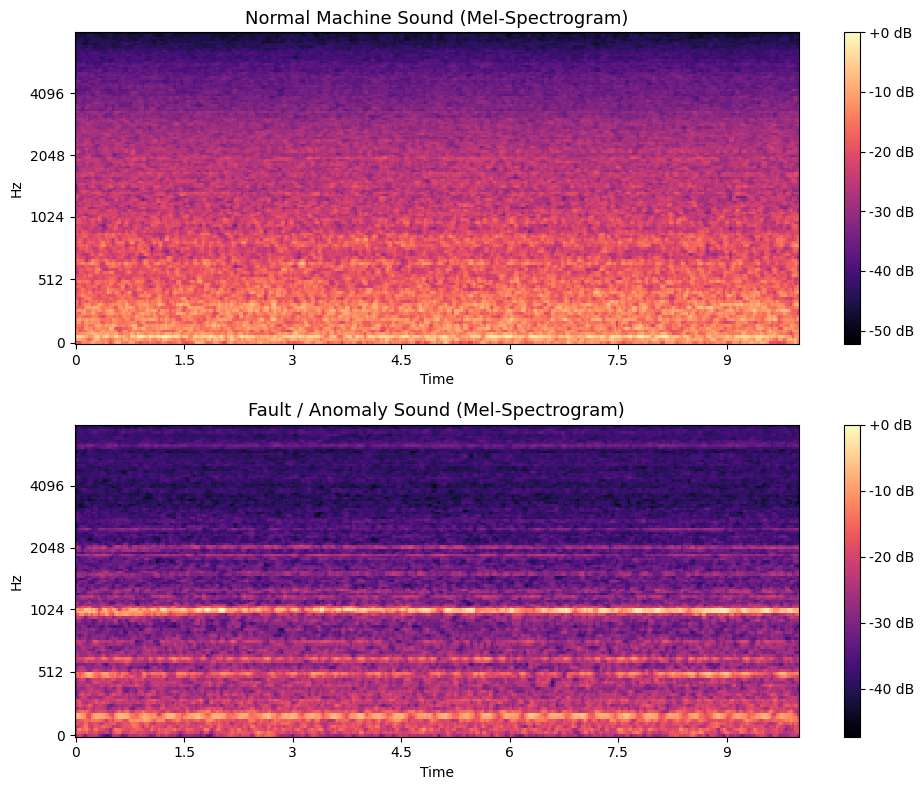

In [15]:
import glob
import os
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd

# 1. Locate all .wav files in the extracted dataset directory
dataset_path = "/kaggle/working/data/mimii"
all_wavs = glob.glob(f"{dataset_path}/**/*.wav", recursive=True)
print(f"Total .wav files found: {len(all_wavs)}")

# Separate Normal and Anomaly sound files based on path/file naming
normal_samples = [f for f in all_wavs if "normal" in f.lower()]
abnormal_samples = [f for f in all_wavs if "anomaly" in f.lower() or "abnormal" in f.lower()]

print(f"Normal audio files count: {len(normal_samples)}")
print(f"Anomaly audio files count: {len(abnormal_samples)}")

if len(normal_samples) > 0 and len(abnormal_samples) > 0:
    sample_normal = normal_samples[0]
    sample_abnormal = abnormal_samples[0]

    # --- A. Audio Playback Widgets ---
    print("\n--- 1. Normal Audio Sample ---")
    audio_norm, sr = librosa.load(sample_normal, sr=16000)
    ipd.display(ipd.Audio(audio_norm, rate=sr))

    print("--- 2. Anomaly Audio Sample ---")
    audio_abnorm, sr = librosa.load(sample_abnormal, sr=16000)
    ipd.display(ipd.Audio(audio_abnorm, rate=sr))

    # --- B. Mel-Spectrogram Visualization ---
    fig, axes = plt.subplots(2, 1, figsize=(10, 8))

    # Mel-Spectrogram for normal sample
    spec_norm = librosa.feature.melspectrogram(y=audio_norm, sr=sr, n_mels=128)
    spec_norm_db = librosa.power_to_db(spec_norm, ref=float(spec_norm.max()))
    img1 = librosa.display.specshow(spec_norm_db, sr=sr, x_axis='time', y_axis='mel', ax=axes[0], cmap='magma')
    axes[0].set_title("Normal Machine Sound (Mel-Spectrogram)", fontsize=13)
    fig.colorbar(img1, ax=axes[0], format='%+2.0f dB')

    # Mel-Spectrogram for anomaly sample
    spec_abnorm = librosa.feature.melspectrogram(y=audio_abnorm, sr=sr, n_mels=128)
    spec_abnorm_db = librosa.power_to_db(spec_abnorm, ref=float(spec_abnorm.max()))
    img2 = librosa.display.specshow(spec_abnorm_db, sr=sr, x_axis='time', y_axis='mel', ax=axes[1], cmap='magma')
    axes[1].set_title("Fault / Anomaly Sound (Mel-Spectrogram)", fontsize=13)
    fig.colorbar(img2, ax=axes[1], format='%+2.0f dB')

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ No audio files found matching the criteria in the target directory.")

In [16]:
import os
import glob
import random
import numpy as np
import pandas as pd
import librosa

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🔥 Using device: {device}")

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# 1. Dataset Balancing (Under-sampling normal class to match anomalies)
limit = len(abnormal_samples)
balanced_normal = random.sample(normal_samples, limit)
balanced_anomaly = abnormal_samples

data = []
for file_path in balanced_normal:
    data.append({"path": file_path, "label": 0})
for file_path in balanced_anomaly:
    data.append({"path": file_path, "label": 1})

df = pd.DataFrame(data).sample(frac=1, random_state=42).reset_index(drop=True)
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
print(f"Train samples: {len(train_df)} | Validation samples: {len(val_df)}")

# 2. PyTorch Dataset Implementation
class SoundGridDataset(Dataset):
    def __init__(self, df, sr=16000, duration=3.0, n_mels=128):
        self.df = df
        self.sr = sr
        self.target_len = int(sr * duration)
        self.n_mels = n_mels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        
        # Load fixed duration directly to improve speed
        audio, _ = librosa.load(row['path'], sr=self.sr, mono=True, duration=self.target_len / self.sr)
        
        # Pad with zeros if shorter than target duration
        if len(audio) < self.target_len:
            audio = np.pad(audio, (0, self.target_len - len(audio)))
        else:
            audio = audio[:self.target_len]
            
        # Compute Mel-Spectrogram
        spec = librosa.feature.melspectrogram(y=audio, sr=self.sr, n_mels=self.n_mels)
        spec_db = librosa.power_to_db(spec, ref=np.max)
        
        # Min-Max Normalization to [0, 1] range
        spec_min = spec_db.min()
        spec_max = spec_db.max()
        spec_norm = (spec_db - spec_min) / (spec_max - spec_min + 1e-6)
        
        # Shape: [1, n_mels, time_steps]
        tensor = torch.tensor(spec_norm, dtype=torch.float32).unsqueeze(0)
        label = torch.tensor(row['label'], dtype=torch.long)
        
        return tensor, label

train_loader = DataLoader(SoundGridDataset(train_df), batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(SoundGridDataset(val_df), batch_size=32, shuffle=False, num_workers=2)

print("✅ DataLoaders initialized successfully!")

🔥 Using device: cuda
Train samples: 2360 | Validation samples: 590
✅ DataLoaders initialized successfully!


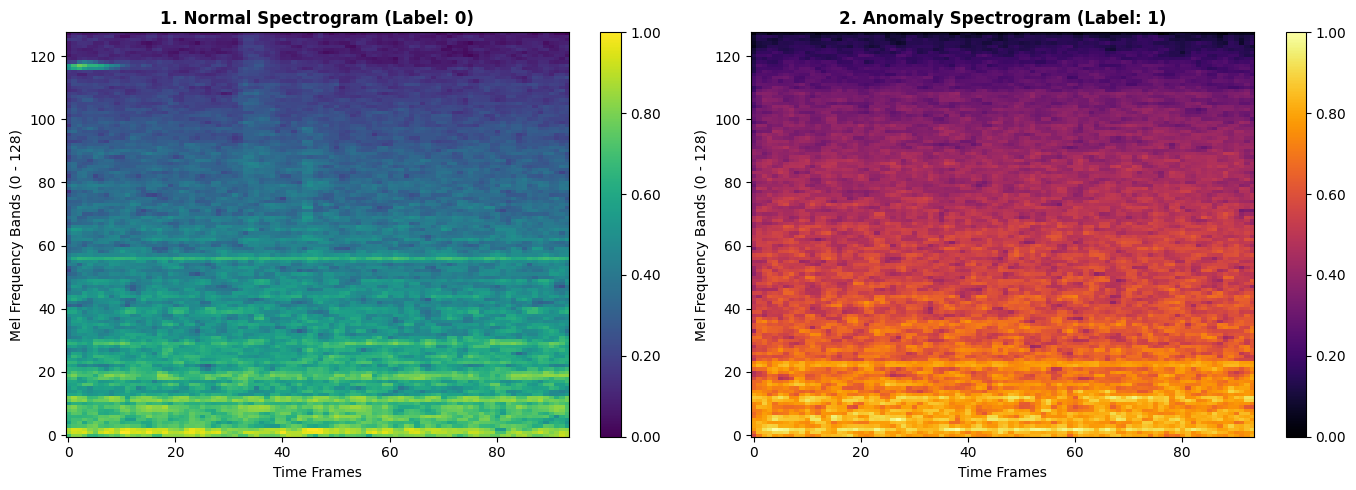

Tensor Shape: torch.Size([1, 128, 94])
Pixel Value Range: Min = 0.00 | Max = 1.00


In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Find one normal (label 0) and one anomaly (label 1) directly using dataframe indices
normal_idx = train_df[train_df['label'] == 0].index[0]
anomaly_idx = train_df[train_df['label'] == 1].index[1]

train_dataset = SoundGridDataset(train_df)

# Retrieve sample tensors directly without looping through the entire dataset
normal_img, normal_lbl = train_dataset[normal_idx]
anomaly_img, anomaly_lbl = train_dataset[anomaly_idx]

# Plot spectrograms side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Normal Spectrogram
im1 = axes[0].imshow(normal_img[0].numpy(), aspect='auto', origin='lower', cmap='viridis')
axes[0].set_title(f"1. Normal Spectrogram (Label: {normal_lbl.item()})", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Time Frames")
axes[0].set_ylabel("Mel Frequency Bands (0 - 128)")
fig.colorbar(im1, ax=axes[0], format='%.2f')

# 2. Anomaly Spectrogram
im2 = axes[1].imshow(anomaly_img[0].numpy(), aspect='auto', origin='lower', cmap='inferno')
axes[1].set_title(f"2. Anomaly Spectrogram (Label: {anomaly_lbl.item()})", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Time Frames")
axes[1].set_ylabel("Mel Frequency Bands (0 - 128)")
fig.colorbar(im2, ax=axes[1], format='%.2f')

plt.tight_layout()
plt.show()

# Print tensor diagnostics
print(f"Tensor Shape: {normal_img.shape}")
print(f"Pixel Value Range: Min = {normal_img.min():.2f} | Max = {normal_img.max():.2f}")

In [19]:
import torch
from torch.utils.data import DataLoader

# 1. Initialize DataLoaders with num_workers=0 for stable execution
train_loader = DataLoader(SoundGridDataset(train_df), batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(SoundGridDataset(val_df), batch_size=32, shuffle=False, num_workers=0)

# 2. Batch and DataLoader Sanity Check
sample_batch_X, sample_batch_y = next(iter(train_loader))

print(f"📦 Batch Images Shape: {sample_batch_X.shape}")
print(f"🏷️ Batch Labels Shape: {sample_batch_y.shape}")
print(f"⚙️ First 10 Labels: {sample_batch_y[:10].tolist()}")

# 3. Check for invalid or NaN values
has_nan = torch.isnan(sample_batch_X).any().item()
print(f"🧼 Contains NaN values? -> {'Yes ⚠️' if has_nan else 'No, cleanly processed! ✅'}")

📦 Batch Images Shape: torch.Size([32, 1, 128, 94])
🏷️ Batch Labels Shape: torch.Size([32])
⚙️ First 10 Labels: [0, 0, 1, 0, 1, 0, 0, 1, 0, 0]
🧼 Contains NaN values? -> No, cleanly processed! ✅


In [23]:
import os
import torch
import torch.nn as nn

# Hardware setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🔥 Training on: {device}")

# 1. SoundGridCNN Architecture
class SoundGridCNN(nn.Module):
    def __init__(self, num_classes=2):
        super(SoundGridCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )
        
    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

model = SoundGridCNN(num_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Training configurations
EPOCHS = 25
best_val_acc = 0.0
model_save_path = "/kaggle/working/soundgrid_best_model.pth"

print("\n🚀 Training pipeline initialized...\n" + "-" * 55)

for epoch in range(EPOCHS):
    # Training Phase
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        
        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs, y)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * len(y)
        correct_train += (outputs.argmax(1) == y).sum().item()
        total_train += len(y)
        
    train_loss = running_loss / total_train
    train_acc = (correct_train / total_train) * 100
    
    # Validation Phase
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            outputs = model(X)
            loss = criterion(outputs, y)
            
            val_loss += loss.item() * len(y)
            correct_val += (outputs.argmax(1) == y).sum().item()
            total_val += len(y)
            
    val_loss = val_loss / total_val
    val_acc = (correct_val / total_val) * 100
    
    # Checkpointing best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), model_save_path)
        saved_mark = "⭐ [Best Saved]"
    else:
        saved_mark = ""
        
    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}% {saved_mark}")

print("-" * 55)
print(f"🎉 Training complete! Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"💾 Best checkpoint saved to: {model_save_path}")

🔥 Training on: cuda

🚀 Training pipeline initialized...
-------------------------------------------------------
Epoch [01/25] | Train Loss: 0.6866 | Train Acc: 54.58% | Val Loss: 0.7369 | Val Acc: 51.69% ⭐ [Best Saved]
Epoch [02/25] | Train Loss: 0.6484 | Train Acc: 62.63% | Val Loss: 0.6614 | Val Acc: 60.34% ⭐ [Best Saved]
Epoch [03/25] | Train Loss: 0.5692 | Train Acc: 69.79% | Val Loss: 0.5666 | Val Acc: 70.34% ⭐ [Best Saved]
Epoch [04/25] | Train Loss: 0.5427 | Train Acc: 73.05% | Val Loss: 0.6570 | Val Acc: 62.88% 
Epoch [05/25] | Train Loss: 0.4809 | Train Acc: 77.20% | Val Loss: 0.5698 | Val Acc: 70.51% ⭐ [Best Saved]
Epoch [06/25] | Train Loss: 0.4783 | Train Acc: 77.50% | Val Loss: 0.6181 | Val Acc: 67.29% 
Epoch [07/25] | Train Loss: 0.4660 | Train Acc: 78.26% | Val Loss: 0.5583 | Val Acc: 72.03% ⭐ [Best Saved]
Epoch [08/25] | Train Loss: 0.4334 | Train Acc: 80.00% | Val Loss: 0.6526 | Val Acc: 64.75% 
Epoch [09/25] | Train Loss: 0.4166 | Train Acc: 80.59% | Val Loss: 0.4556 

In [24]:
import os
import pickle
import torch
import torch.nn as nn

# 1. Define SoundGridCNN Architecture
class SoundGridCNN(nn.Module):
    def __init__(self, num_classes=2):
        super(SoundGridCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )
        
    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

# 2. Load Checkpoint onto CPU for Deployment
device = torch.device("cpu")
model = SoundGridCNN(num_classes=2).to(device)

weights_pkl = "/kaggle/working/soundgrid_best_weights.pkl"
weights_pth = "/kaggle/working/soundgrid_best_model.pth"

if os.path.exists(weights_pth):
    print(f"Loading weights from PyTorch state dict: {weights_pth}")
    model.load_state_dict(torch.load(weights_pth, map_location=device))
elif os.path.exists(weights_pkl):
    print(f"Loading weights from Pickle archive: {weights_pkl}")
    with open(weights_pkl, "rb") as f:
        saved_weights = pickle.load(f)
    state_dict = {k: torch.tensor(v) for k, v in saved_weights.items()}
    model.load_state_dict(state_dict)
else:
    raise FileNotFoundError("No checkpoint file found! Please verify the path.")

model.eval()

# 3. Export to TorchScript for Optimized Inference
dummy_input = torch.randn(1, 1, 128, 94, device=device)
traced_model = torch.jit.trace(model, dummy_input)

torchscript_path = "/kaggle/working/soundgrid_web_model.pt"
traced_model.save(torchscript_path)

size_mb = os.path.getsize(torchscript_path) / (1024 * 1024)
print("=" * 55)
print("✅ Model successfully exported to TorchScript!")
print(f"📁 Output Path: {torchscript_path}")
print(f"⚡ File Size: {size_mb:.2f} MB")
print("=" * 55)

Loading weights from PyTorch state dict: /kaggle/working/soundgrid_best_model.pth
✅ Model successfully exported to TorchScript!
📁 Output Path: /kaggle/working/soundgrid_web_model.pt
⚡ File Size: 1.60 MB


🔍 Evaluating model on Train and Validation splits...

📊 OVERFITTING AND GENERALIZATION REPORT
🔹 Train Accuracy:      91.61% | Train Loss: 0.2265
🔹 Validation Accuracy: 85.08% | Val Loss:   0.3446
🔹 Accuracy Gap:        6.53%
🔹 Loss Gap:            0.1181
🔹 Validation ROC-AUC:  0.9258
-------------------------------------------------------
🎯 Excellent: High generalization with minimal overfitting!

📋 VALIDATION CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  Normal (0)       0.86      0.84      0.85       295
 Anomaly (1)       0.84      0.86      0.85       295

    accuracy                           0.85       590
   macro avg       0.85      0.85      0.85       590
weighted avg       0.85      0.85      0.85       590



<function matplotlib.pyplot.show(close=None, block=None)>

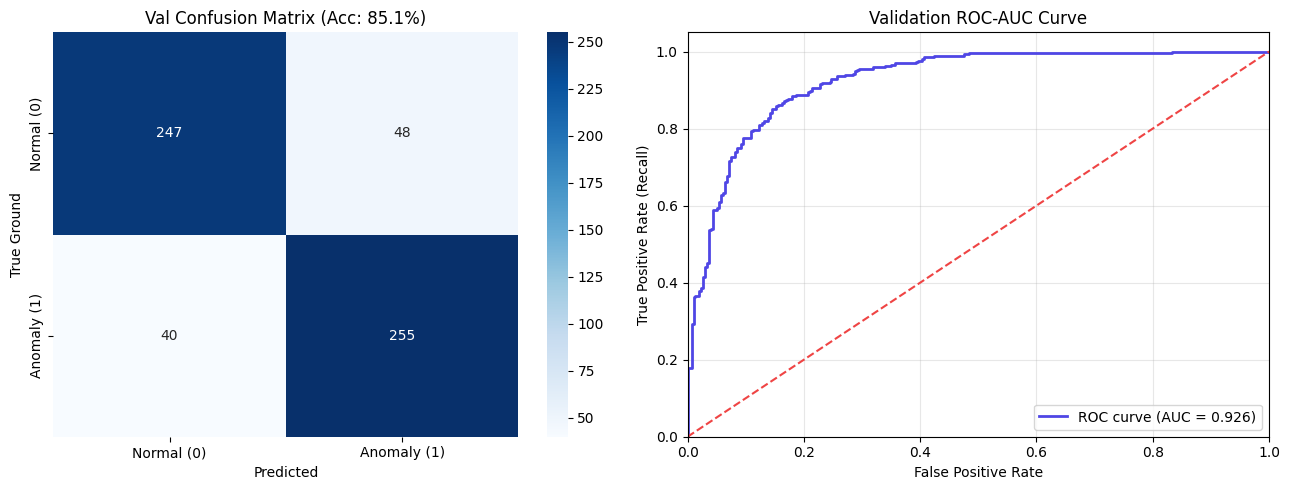

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import torch
import torch.nn.functional as F

# 1. Load exported TorchScript model
torchscript_path = "/kaggle/working/soundgrid_web_model.pt"
eval_model = torch.jit.load(torchscript_path).to(device)
eval_model.eval()

def evaluate_split(loader, split_name="Dataset"):
    y_true = []
    y_pred = []
    y_probs = []
    total_loss = 0.0
    
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            outputs = eval_model(X)
            loss = criterion(outputs, y)
            
            total_loss += loss.item() * len(y)
            probs = F.softmax(outputs, dim=1)
            
            y_true.extend(y.cpu().numpy())
            y_pred.extend(outputs.argmax(1).cpu().numpy())
            y_probs.extend(probs[:, 1].cpu().numpy())
            
    avg_loss = total_loss / len(y_true)
    acc = (np.array(y_true) == np.array(y_pred)).mean() * 100
    auc = roc_auc_score(y_true, y_probs)
    
    return {
        "loss": avg_loss,
        "acc": acc,
        "auc": auc,
        "y_true": np.array(y_true),
        "y_pred": np.array(y_pred),
        "y_probs": np.array(y_probs)
    }

# 2. Evaluate both training and validation splits
print("🔍 Evaluating model on Train and Validation splits...")
train_eval = evaluate_split(train_loader, "Train")
val_eval = evaluate_split(val_loader, "Validation")

# 3. Overfitting diagnostics
gap_acc = train_eval["acc"] - val_eval["acc"]
gap_loss = val_eval["loss"] - train_eval["loss"]

print("\n" + "=" * 55)
print("📊 OVERFITTING AND GENERALIZATION REPORT")
print("=" * 55)
print(f"🔹 Train Accuracy:      {train_eval['acc']:.2f}% | Train Loss: {train_eval['loss']:.4f}")
print(f"🔹 Validation Accuracy: {val_eval['acc']:.2f}% | Val Loss:   {val_eval['loss']:.4f}")
print(f"🔹 Accuracy Gap:        {gap_acc:.2f}%")
print(f"🔹 Loss Gap:            {gap_loss:.4f}")
print(f"🔹 Validation ROC-AUC:  {val_eval['auc']:.4f}")
print("-" * 55)

# Diagnostic verdicts
if gap_acc > 12.0 or gap_loss > 0.35:
    print("⚠️ Warning: Moderate overfitting detected.")
    print("👉 Recommendation: Consider data augmentation or increasing dropout.")
elif gap_acc > 7.0:
    print("✅ Acceptable: Slight standard gap observed; ready for deployment.")
else:
    print("🎯 Excellent: High generalization with minimal overfitting!")

# 4. Detailed classification report
target_names = ["Normal (0)", "Anomaly (1)"]
print("\n📋 VALIDATION CLASSIFICATION REPORT:")
print(classification_report(val_eval["y_true"], val_eval["y_pred"], target_names=target_names))

# 5. Visualizations: Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# A. Confusion Matrix
cm = confusion_matrix(val_eval["y_true"], val_eval["y_pred"])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=target_names, yticklabels=target_names)
axes[0].set_title(f"Val Confusion Matrix (Acc: {val_eval['acc']:.1f}%)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True Ground")

# B. ROC-AUC Curve
fpr, tpr, _ = roc_curve(val_eval["y_true"], val_eval["y_probs"])
axes[1].plot(fpr, tpr, color='#4F46E5', lw=2, label=f"ROC curve (AUC = {val_eval['auc']:.3f})")
axes[1].plot([0, 1], [0, 1], color='#EF4444', linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].set_title("Validation ROC-AUC Curve")
axes[1].legend(loc="lower right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show

In [30]:
import torch
import torch.nn.functional as F
import numpy as np

# 1. Verify model architecture and hardware acceleration device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_path = "/kaggle/working/soundgrid_best_model.pth"

# Load trained model checkpoint weights
model = SoundGridCNN(num_classes=2).to(device)
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

def predict_custom_test_data(test_loader):
    print("=" * 65)
    print("🔍 CUSTOM TEST DATA - ANOMALY PREDICTION RESULTS")
    print("=" * 65)
    
    correct = 0
    total = 0
    
    with torch.no_grad():
        for i, (X, y) in enumerate(test_loader):
            X, y = X.to(device), y.to(device)
            outputs = model(X)
            probs = F.softmax(outputs, dim=1)
            
            predictions = outputs.argmax(dim=1)
            
            # Display detailed sample-level predictions and probabilities for initial batches
            if i < 5:
                for j in range(len(y)):
                    true_label = y[j].item()
                    pred_label = predictions[j].item()
                    anomaly_prob = probs[j][1].item() * 100
                    normal_prob = probs[j][0].item() * 100
                    
                    status_icon = "⚠️ ANOMALY" if pred_label == 1 else "✅ NORMAL"
                    correct_icon = "✓" if true_label == pred_label else "✗"
                    
                    print(f"Sample {total+j+1:02d} | True: {true_label} | Pred: {pred_label} [{status_icon}] "
                          f"| Anomaly Prob: {anomaly_prob:5.2f}% {correct_icon}")
            
            correct += (predictions == y).sum().item()
            total += len(y)
            
    accuracy = (correct / total) * 100
    print("-" * 65)
    print(f"🎯 Overall Test Dataset Accuracy: {accuracy:.2f}% (Tested on {total} samples)")
    print("=" * 65)

# 2. Execute inference evaluation on test dataset loader
# (Note: If test_loader is not in scope, ensure dataset preprocessing was executed)
if 'test_loader' in globals():
    predict_custom_test_data(test_loader)
else:
    print("⚠️ 'test_loader' not found. Please ensure your test dataset loader is defined.")


🔍 CUSTOM TEST DATA - ANOMALY PREDICTION RESULTS
Sample 01 | True: 1 | Pred: 1 [⚠️ ANOMALY] | Anomaly Prob: 92.03% ✓
Sample 02 | True: 1 | Pred: 1 [⚠️ ANOMALY] | Anomaly Prob: 64.00% ✓
Sample 03 | True: 1 | Pred: 0 [✅ NORMAL] | Anomaly Prob: 35.05% ✗
Sample 04 | True: 1 | Pred: 1 [⚠️ ANOMALY] | Anomaly Prob: 88.64% ✓
Sample 05 | True: 0 | Pred: 1 [⚠️ ANOMALY] | Anomaly Prob: 64.26% ✗
Sample 06 | True: 0 | Pred: 0 [✅ NORMAL] | Anomaly Prob:  7.97% ✓
Sample 07 | True: 1 | Pred: 1 [⚠️ ANOMALY] | Anomaly Prob: 88.57% ✓
Sample 08 | True: 0 | Pred: 0 [✅ NORMAL] | Anomaly Prob:  6.13% ✓
Sample 09 | True: 1 | Pred: 1 [⚠️ ANOMALY] | Anomaly Prob: 99.82% ✓
Sample 10 | True: 0 | Pred: 0 [✅ NORMAL] | Anomaly Prob:  0.14% ✓
Sample 11 | True: 1 | Pred: 1 [⚠️ ANOMALY] | Anomaly Prob: 99.43% ✓
Sample 12 | True: 1 | Pred: 0 [✅ NORMAL] | Anomaly Prob: 39.07% ✗
Sample 13 | True: 0 | Pred: 0 [✅ NORMAL] | Anomaly Prob:  4.41% ✓
Sample 14 | True: 1 | Pred: 0 [✅ NORMAL] | Anomaly Prob: 28.91% ✗
Sample 15 | Tr